In [1]:
import os
from gbheatmodel.path import PROJECT_ROOT

os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from gbheatmodel.path import path_in_data, ensure_dir

from gbheatmodel.cop import average_day_cop_for_heat_pump,day_cop_for_year_grid_sq
from gbheatmodel.runner import run_heat_demand_pipeline, run_heat_profiles_only, run_cop_profiles, run_electric_demand

In [3]:
# 🔧 User inputs for heating demand pipeline

weather_year = 2010        # weather data / patterns year
future_year = 2050         # target future year
FES_year = "2022"          # FES dataset version
FES_scenario = "LW"        # "LW", "CT", "ST", "FS", ...

# Optional: a grid to inspect later
grid_id = "-3.5_56.0"
# heat_pump_type: 'ASHP' or 'GSHP'
# performance_level: 'current', 'good', 'very good'
performance_level= "very good"


In [4]:
HD_profiles = run_heat_profiles_only(
    weather_year=weather_year,
    future_year=future_year,
    FES_year=FES_year,
    scenario=FES_scenario,
)
HD_profiles

✅ All heating profiles already exist. Loading from disk.


{'-0.25_50.75':                              ASHP          GSHP  Gas boiler  Electric storage  \
 2050-01-01 00:00:00  11258.656639  15142.824977    0.022245       4376.303568   
 2050-01-01 00:30:00  11432.756879  15437.775982    0.022006       4486.229197   
 2050-01-01 01:00:00  11802.194533  15943.044839    0.022637       4635.323729   
 2050-01-01 01:30:00  12099.466932  16334.350117    0.023235       4743.733143   
 2050-01-01 02:00:00  12677.736886  17028.991398    0.025089       4909.253344   
 ...                           ...           ...         ...               ...   
 2050-12-31 21:30:00  14402.341976  17189.354432    0.051773       4122.869771   
 2050-12-31 22:00:00  12691.523364  15534.608607    0.041675       3898.181379   
 2050-12-31 22:30:00  11018.155385  13926.605301    0.031541       3683.023992   
 2050-12-31 23:00:00   9766.808681  12727.154130    0.023863       3523.024767   
 2050-12-31 23:30:00   9140.282869  12152.912254    0.019718       3460.363473   
 

In [5]:
cop_profiles = run_cop_profiles(
    weather_year=weather_year,
    future_year=future_year,
    performance_level=performance_level,
    save=True,
)

In [6]:
df_cop_ASHP = cop_profiles["ASHP"]
df_cop_GSHP = cop_profiles["GSHP"]

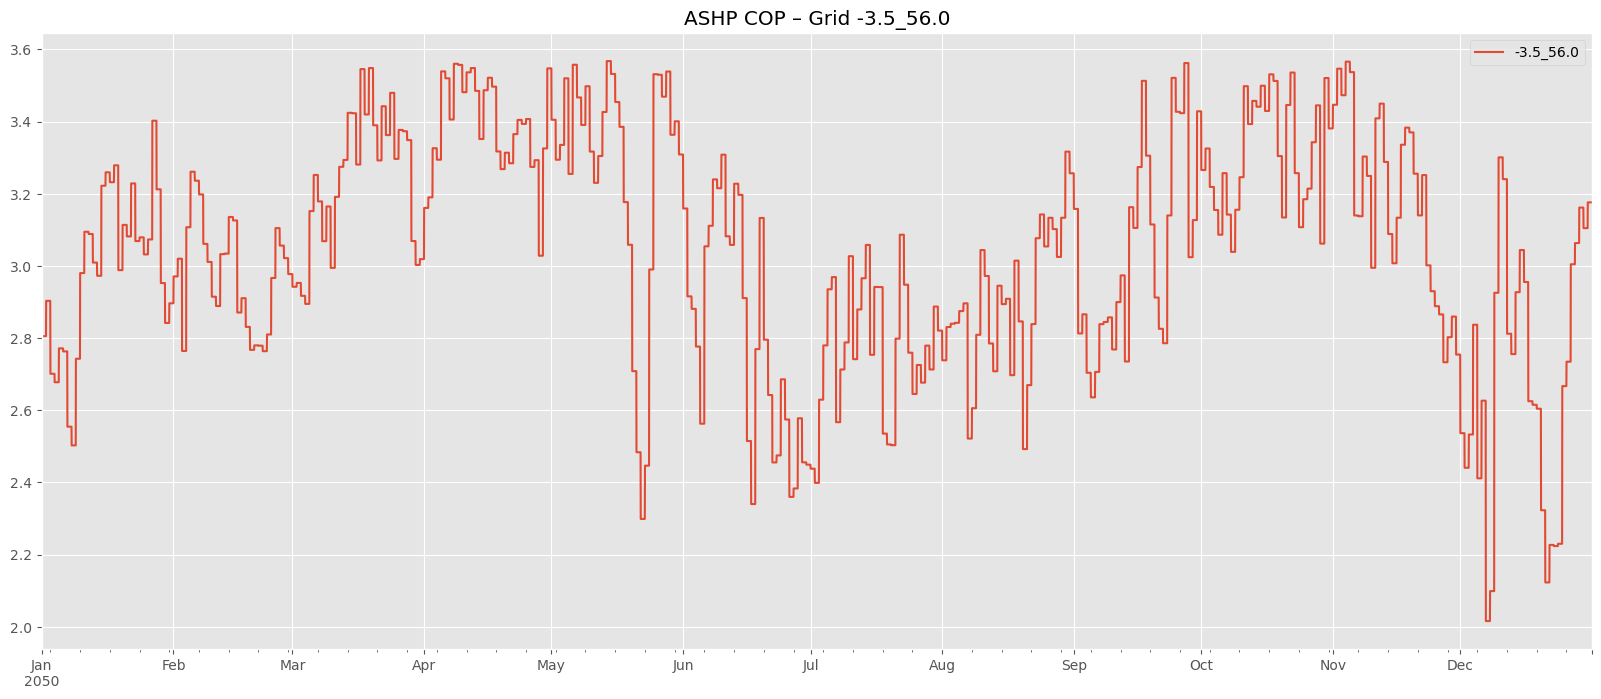

In [7]:
      
df_ASHP_grid_id = df_cop_ASHP[[grid_id]]

plt.style.use("ggplot")
df_ASHP_grid_id.plot(figsize=(20, 8))
plt.title(f"ASHP COP – Grid {grid_id}")
plt.show()

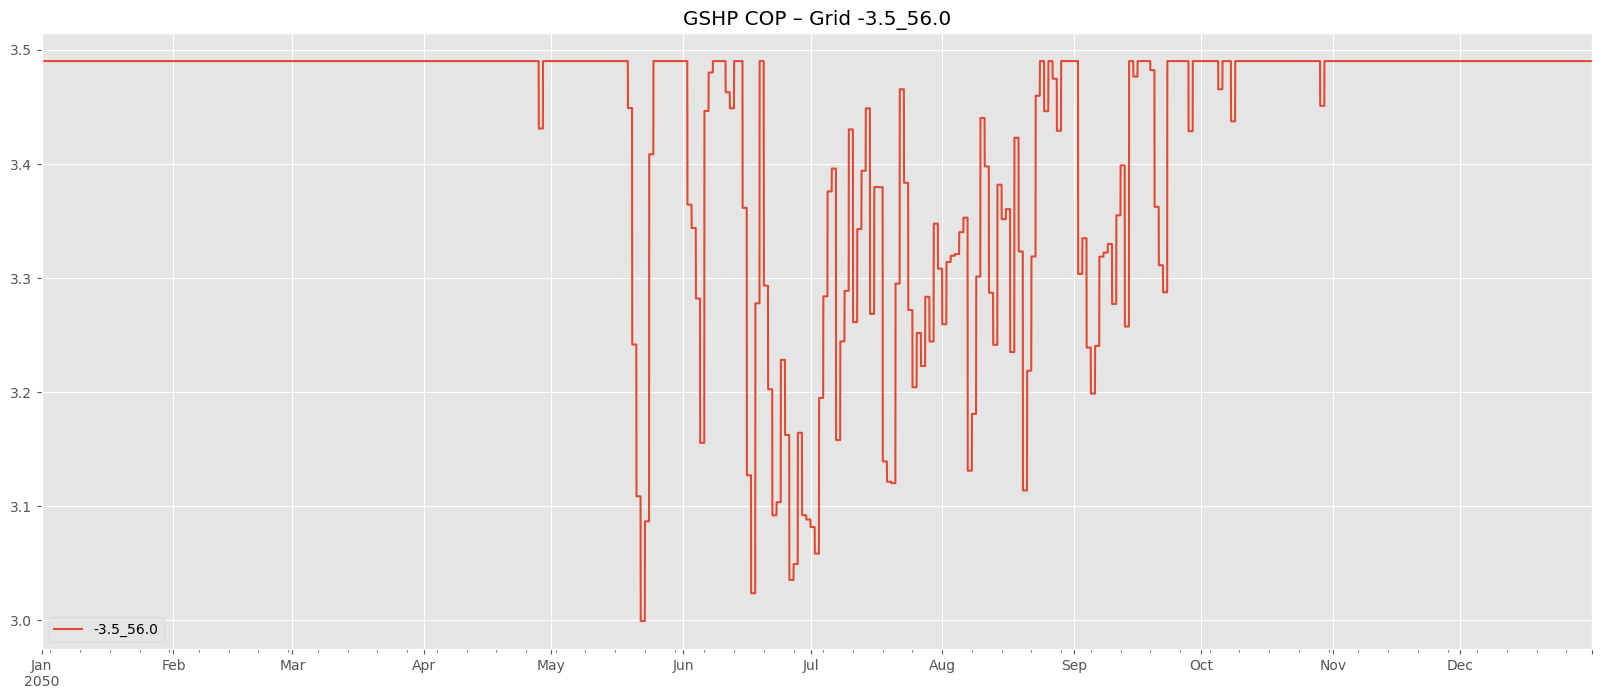

In [8]:
df_GSHP_grid_id = df_cop_GSHP[[grid_id]]

plt.style.use("ggplot")
df_GSHP_grid_id.plot(figsize=(20, 8))
plt.title(f"GSHP COP – Grid {grid_id}")
plt.show()

In [9]:
ed_grid_sqs = run_electric_demand(
    HD_profiles,
    df_cop_ASHP,
    df_cop_GSHP,
    FES_year,
    FES_scenario,
    future_year,
    save=True,
)

In [ ]:
hd_df['2050-01-01 00:00:00': '2050-01-08 00:00:00'].plot.area(figsize=(20,8), cmap='tab20')

In [ ]:
# Select relevant columns
elec_hd_df = hd_df[[
    'ASHP', 'GSHP',
    'Hybrid (ASHP + BioLPG boiler)',
    'Hybrid (ASHP + Hydrogen boiler)',
    'Hybrid (ASHP + Electric resistive)'
]]

# Align all operations by index instead of using .values
elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id]
elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id]

elec_hd_df['Hybrid (ASHP + BioLPG boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + BioLPG boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Hydrogen boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Hydrogen boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Electric resistive) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Electric resistive)'] / df_ASHP_grid_id[grid_id]
    + 0.25 * elec_hd_df['Hybrid (ASHP + Electric resistive)']
)

# Plot
elec_hd_df.loc['2050-01-01 00:00:00':'2050-01-08 00:00:00', [
    'ASHP Elec', 'GSHP Elec',
    'Hybrid (ASHP + BioLPG boiler) Elec',
    'Hybrid (ASHP + Hydrogen boiler) Elec',
    'Hybrid (ASHP + Electric resistive) Elec'
]].plot.area(figsize=(20, 8), cmap='tab20')


In [ ]:
ed_df = elec_hd_df[['ASHP Elec', 'GSHP Elec', 'Hybrid (ASHP + BioLPG boiler) Elec', 'Hybrid (ASHP + Hydrogen boiler) Elec', 'Hybrid (ASHP + Electric resistive) Elec']]
ed_df.sum().plot.bar(figsize=(20,8), cmap='tab20')

In [ ]:
# total in GWh
ed_df.sum().sum() / 1000000